# Two-centre variational energies for the hydrogen molecular ion

Change the range or sampling of nuclear separations. The solver orthonormalises the overlap metric before diagonalising. Compare its grid minimum with the even-state formula and distinguish grid error from the error inherent in the two-orbital basis.

Run this cell with OneSimulation, NumPy and Matplotlib installed. Adjust the parameters and rerun to compare with the reference output below.


Grid minimum R = 2.490 bohr
Total energy = -0.564831 hartree
Binding relative to H + proton = 1.764 eV


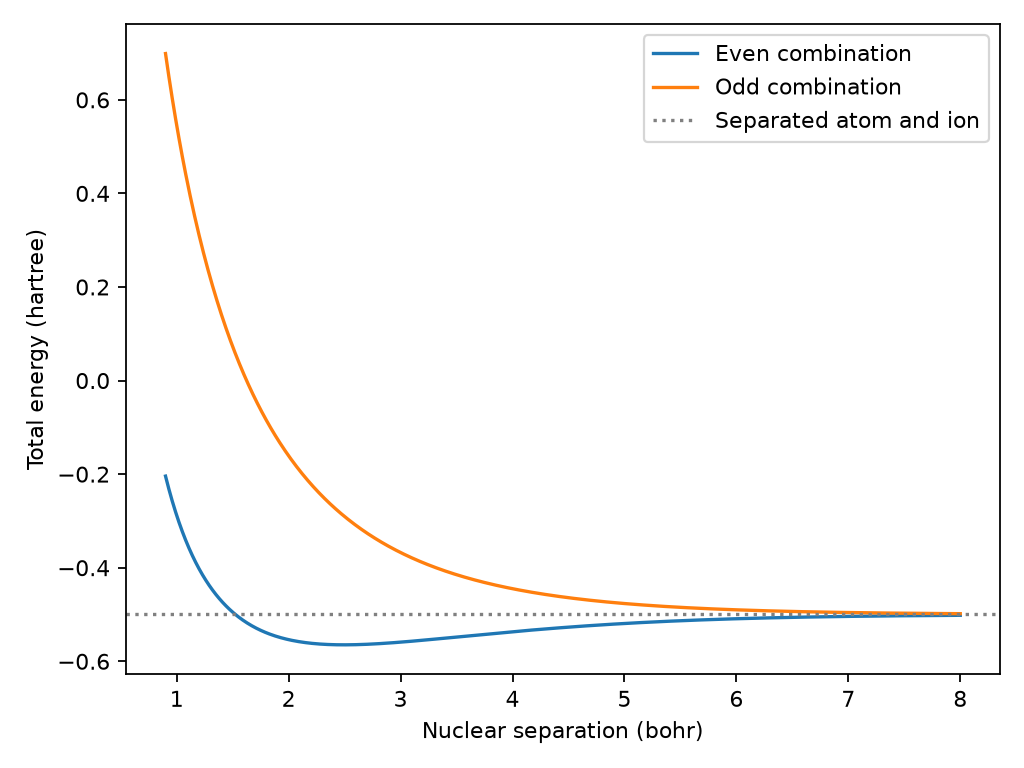

In [1]:
"""Hydrogen molecular ion in a fixed pair of hydrogenic 1s orbitals; atomic units."""
import numpy as np
import matplotlib.pyplot as plt
from onesim.numerics.linear.matrices.dense_linear_algebra import symmetric_eigenvalues

def total_energies(r):
    s = np.exp(-r) * (1 + r + r*r/3)
    j = -1/r + (1 + 1/r) * np.exp(-2*r)
    k = -(1 + r) * np.exp(-r)
    h = np.array([[-0.5+j, -0.5*s+k], [-0.5*s+k, -0.5+j]])
    metric = np.array([[1.0, s], [s, 1.0]])
    chol = np.linalg.cholesky(metric)
    left = np.linalg.solve(chol, h)
    orthogonal = np.linalg.solve(chol, left.T).T
    return symmetric_eigenvalues(orthogonal) + 1/r

distance = np.linspace(0.9, 8.0, 711)
bonding, antibonding = np.array([total_energies(r) for r in distance]).T
i = np.argmin(bonding)
print(f"Grid minimum R = {distance[i]:.3f} bohr")
print(f"Total energy = {bonding[i]:.6f} hartree")
print(f"Binding relative to H + proton = {(-0.5-bonding[i])*27.2114:.3f} eV")
plt.plot(distance, bonding, label="Even combination")
plt.plot(distance, antibonding, label="Odd combination")
plt.axhline(-0.5, linestyle=":", color="grey", label="Separated atom and ion")
plt.xlabel("Nuclear separation (bohr)")
plt.ylabel("Total energy (hartree)")
plt.legend()
plt.tight_layout()
plt.savefig("physics-molecular-ion.png", dpi=160)

plt.show()
